# Analysis of Maternal Health Data.

## Data Inspection and Understanding.

### Loading the Data.

In [1]:
# Importing the libraries required.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the stata dataset from the NDHS portal.
df = pd.read_stata("Downloads/NG_2024_DHS_10262026_113_262964/NGIR8BDT/NGIR8BFL.dta", convert_categoricals = False)

### Inspecting the Data.

In [2]:
# Displaying the first 5 rows.
df.head()

,caseid,v000,v001,v002,v003,v004,v005,v006,v007,v008,...,s626bc_3,s626bc_4,s626bc_5,s626bc_6,s631a_1,s631a_2,s631a_3,s631a_4,s631a_5,s631a_6
0,1 2 2,NG8,1,2,2,1,491963,1,2024,1489,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1 2 4,NG8,1,2,4,1,491963,1,2024,1489,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 6 2,NG8,1,6,2,1,491963,1,2024,1489,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1 9 5,NG8,1,9,5,1,491963,1,2024,1489,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1 9 7,NG8,1,9,7,1,491963,1,2024,1489,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Displaying the shape of the dataset.
df.shape

(39050, 6411)

In [4]:
# Displaying the columns.
print(df.columns.tolist())

['caseid', 'v000', 'v001', 'v002', 'v003', 'v004', 'v005', 'v006', 'v007', 'v008', 'v008a', 'v009', 'v010', 'v011', 'v012', 'v013', 'v014', 'v015', 'v016', 'v017', 'v018', 'v019', 'v019a', 'v020', 'v021', 'v022', 'v023', 'v024', 'v025', 'v026', 'v027', 'v028', 'v029', 'v030', 'v031', 'v032', 'v034', 'v040', 'v042', 'v044', 'v045a', 'v045b', 'v045c', 'v046', 'v047', 'v048', 'v101', 'v102', 'v103', 'v104', 'v105', 'v105a', 'v106', 'v107', 'v113', 'v115', 'v116', 'v119', 'v120', 'v121', 'v122', 'v123', 'v124', 'v125', 'v127', 'v128', 'v129', 'v130', 'v131', 'v133', 'v134', 'v135', 'v136', 'v137', 'v138', 'v139', 'v140', 'v141', 'v149', 'v150', 'v151', 'v152', 'v153', 'awfactt', 'awfactu', 'awfactr', 'awfacte', 'awfactw', 'v155', 'v156', 'v157', 'v158', 'v159', 'v160', 'v161', 'v166', 'v167', 'v168', 'v169a', 'v169b', 'v169c', 'v170', 'v171a', 'v171b', 'v172', 'v173', 'v174m', 'v174y', 'v175', 'v176', 'v177', 'v190', 'v191', 'v190a', 'v191a', 'ml101', 'bidx_01', 'bidx_02', 'bidx_03', 'bidx

In [5]:
# Displaying the general overiew of the dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39050 entries, 0 to 39049
Columns: 6411 entries, caseid to s631a_6
dtypes: float64(6031), int16(21), int32(4), int8(351), object(4)
memory usage: 1.8+ GB


#### Observation.
- The dataset is a complex one, having 6,411 columns and 39,050 rows.
- It has columns with coded names and we haave to refer back to the NDHS codebook to know the meaning of each ones.
- With the dataset having a large number of variables, we have to identify the ones relevant to maternal health.

### Finding the relevant variables for maternal health.

In [6]:
# Dislaying the first 100 columns
print(df.columns[:100].tolist())

['caseid', 'v000', 'v001', 'v002', 'v003', 'v004', 'v005', 'v006', 'v007', 'v008', 'v008a', 'v009', 'v010', 'v011', 'v012', 'v013', 'v014', 'v015', 'v016', 'v017', 'v018', 'v019', 'v019a', 'v020', 'v021', 'v022', 'v023', 'v024', 'v025', 'v026', 'v027', 'v028', 'v029', 'v030', 'v031', 'v032', 'v034', 'v040', 'v042', 'v044', 'v045a', 'v045b', 'v045c', 'v046', 'v047', 'v048', 'v101', 'v102', 'v103', 'v104', 'v105', 'v105a', 'v106', 'v107', 'v113', 'v115', 'v116', 'v119', 'v120', 'v121', 'v122', 'v123', 'v124', 'v125', 'v127', 'v128', 'v129', 'v130', 'v131', 'v133', 'v134', 'v135', 'v136', 'v137', 'v138', 'v139', 'v140', 'v141', 'v149', 'v150', 'v151', 'v152', 'v153', 'awfactt', 'awfactu', 'awfactr', 'awfacte', 'awfactw', 'v155', 'v156', 'v157', 'v158', 'v159', 'v160', 'v161', 'v166', 'v167', 'v168', 'v169a', 'v169b']


#### Note.
- Variables that begins with 'm' often represents maternity-related information in DHS datasets.

In [7]:
# Finding variables that begins with 'm'.
maternity_variables = [
    column for column in df.columns
    if column.lower().startswith('m')
]

# Displaying the first 100 variables.
print(maternity_variables[:100])

# Displaying the number of variables found.
print()
print("Total Matching Variables:", len(maternity_variables))

['ml101', 'midx_1', 'midx_2', 'midx_3', 'midx_4', 'midx_5', 'midx_6', 'midxp_1', 'midxp_2', 'midxp_3', 'midxp_4', 'midxp_5', 'midxp_6', 'm1_1', 'm1_2', 'm1_3', 'm1_4', 'm1_5', 'm1_6', 'm1a_1', 'm1a_2', 'm1a_3', 'm1a_4', 'm1a_5', 'm1a_6', 'm1b_1', 'm1b_2', 'm1b_3', 'm1b_4', 'm1b_5', 'm1b_6', 'm1c_1', 'm1c_2', 'm1c_3', 'm1c_4', 'm1c_5', 'm1c_6', 'm1d_1', 'm1d_2', 'm1d_3', 'm1d_4', 'm1d_5', 'm1d_6', 'm1e_1', 'm1e_2', 'm1e_3', 'm1e_4', 'm1e_5', 'm1e_6', 'm2a_1', 'm2a_2', 'm2a_3', 'm2a_4', 'm2a_5', 'm2a_6', 'm2b_1', 'm2b_2', 'm2b_3', 'm2b_4', 'm2b_5', 'm2b_6', 'm2c_1', 'm2c_2', 'm2c_3', 'm2c_4', 'm2c_5', 'm2c_6', 'm2d_1', 'm2d_2', 'm2d_3', 'm2d_4', 'm2d_5', 'm2d_6', 'm2e_1', 'm2e_2', 'm2e_3', 'm2e_4', 'm2e_5', 'm2e_6', 'm2f_1', 'm2f_2', 'm2f_3', 'm2f_4', 'm2f_5', 'm2f_6', 'm2g_1', 'm2g_2', 'm2g_3', 'm2g_4', 'm2g_5', 'm2g_6', 'm2h_1', 'm2h_2', 'm2h_3', 'm2h_4', 'm2h_5', 'm2h_6', 'm2i_1', 'm2i_2', 'm2i_3']

Total Matching Variables: 1940


#### Note.
- 1,940 variables start with 'm' and that is a lot to work with regarding the scope of this project.
- We checked for important maternity health indicators and the ones commonly used for maternal healthcare analysis will be listed below.
- The meaning of the chosen variables would be explained in this project's data dictionary.

### Checking for relevant variables in the dataset.

In [8]:
# Creating a list of variables to be used.
variables_to_check = [
    'caseid', 'v012', 'v025', 'v106', 'v190',
    'm1_1', 'm2_1', 'm3_1', 'm14_1', 'm15_1', 'm17_1'
]

# Showing which of the variables exist in the dataset.
available_variables = [
    column for column in variables_to_check
    if column in df.columns
]

# Displaying the available variables.
print("Available Variables:")
print(available_variables)

Available Variables:
['caseid', 'v012', 'v025', 'v106', 'v190', 'm1_1', 'm14_1', 'm15_1', 'm17_1']


In [9]:
# Variables that are not available in the dataset.
print("Variables Not Found:")
print([
    column for column in variables_to_check
    if column not in df.columns
])

Variables Not Found:
['m2_1', 'm3_1']


### Creating the dataset to work with (without modifying the original dataset).

In [10]:
# Creating a smaller dataset containing only the selected columns.
maternal_df = df[available_variables.copy()]

# Displaying the shape of the dataset to validate.
print("Dataset shape:", maternal_df.shape)

Dataset shape: (39050, 9)


In [11]:
# Displaying the first 20 rows of the dataset vertically.
maternal_df.head(20).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
caseid,1 2 2,1 2 4,1 6 2,1 9 5,1 9 7,1 10 2,1 13 2,1 15 1,1 16 3,1 18 2,1 18 4,1 19 2,1 21 2,1 22 2,1 22 8,1 24 1,1 28 5,1 29 2,1 32 2,1 34 2
v012,35,17,36,21,19,35,22,45,18,41,18,32,32,41,18,48,17,47,30,20
v025,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
v106,0,0,0,0,0,0,2,0,0,0,2,0,0,0,2,0,0,0,1,0
v190,2,2,2,2,2,2,3,2,2,3,3,2,2,2,2,2,2,2,1,2
m1_1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0
m14_1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0
m15_1,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,11.0
m17_1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [12]:
# Displaying the general overview of the dataset.
maternal_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39050 entries, 0 to 39049
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   caseid  39050 non-null  object 
 1   v012    39050 non-null  int8   
 2   v025    39050 non-null  int8   
 3   v106    39050 non-null  int8   
 4   v190    39050 non-null  int8   
 5   m1_1    13754 non-null  float64
 6   m14_1   13968 non-null  float64
 7   m15_1   13968 non-null  float64
 8   m17_1   13968 non-null  float64
dtypes: float64(4), int8(4), object(1)
memory usage: 1.6+ MB


## Data Cleaning and Preparation.

### Checking for Missing Values.

In [13]:
# Getting an overview of the completeness of each variable in a tabular form.
missing_summary = pd.DataFrame({
    'Missing_Count': maternal_df.isnull().sum(),
    'Missing_Percentage': (
        maternal_df.isnull().mean() * 100
    ).round(2)
})

# Displaying the table.
missing_summary

,Missing_Count,Missing_Percentage
caseid,0,0.00
v012,0,0.00
v025,0,0.00
v106,0,0.00
v190,0,0.00
m1_1,25296,64.78
m14_1,25082,64.23
m15_1,25082,64.23
m17_1,25082,64.23


#### Observation.
- All the demographic variables (starting with 'v') are complete with no missing values.
- None of the maternity variables (starting with 'm') has complete records.

In [14]:
# Investigating the values in each maternity variable.
for col in ['m1_1', 'm14_1', 'm15_1', 'm17_1']:
    print("\nVariable:", col)
    print(
        maternal_df[col].value_counts(dropna = False).head(15)
    )


Variable: m1_1
m1_1
NaN    25296
2.0     4851
0.0     4811
3.0     1958
1.0     1837
4.0      143
5.0       76
8.0       66
6.0       10
7.0        2
Name: count, dtype: int64

Variable: m14_1
m14_1
NaN     25082
0.0      3815
4.0      1579
5.0      1553
3.0      1436
6.0      1136
2.0       729
8.0       639
7.0       623
10.0      402
98.0      374
1.0       350
9.0       284
12.0      265
20.0      175
Name: count, dtype: int64

Variable: m15_1
m15_1
NaN     25082
11.0     7017
24.0     1860
31.0     1392
23.0     1292
12.0      548
25.0      430
37.0      413
32.0      327
21.0      146
22.0      139
26.0       84
96.0       84
41.0       65
42.0       59
Name: count, dtype: int64

Variable: m17_1
m17_1
NaN    25082
0.0    13182
1.0      786
Name: count, dtype: int64


#### Observation.
- The records in each of the variables are in forms of numerical codes.

#### Note.
- Before dropping or deleting any row or record, we first have to understand what these variables represent and what their numerical codes mean.

### Undestanding what each numerical code mean.

In [15]:
# Installing the Pyreadstat library to understand that.
%pip install pyreadstat --index-url https://pypi.org/simple

Note: you may need to restart the kernel to use updated packages.


In [16]:
# Importing the library.
import pyreadstat

print("PyreadStat installed successfully")

PyreadStat installed successfully


In [17]:
# Giving the library access to the dataset.
maternal_df, meta = pyreadstat.read_dta(
    "Downloads/NG_2024_DHS_10262026_113_262964/NGIR8BDT/NGIR8BFL.dta",
    metadataonly = True
)

# Understanding the numerical codes for the variables involved in the analysis.
for variable in available_variables:
    print("Variable:", variable)
    print("Description:", meta.column_names_to_labels.get(variable))
    print("Value Labels:", meta.variable_value_labels.get(variable))

Variable: caseid
Description: case identification
Value Labels: None
Variable: v012
Description: respondent's current age
Value Labels: None
Variable: v025
Description: type of place of residence
Value Labels: {1: 'urban', 2: 'rural'}
Variable: v106
Description: highest educational level
Value Labels: {0: 'no education', 1: 'primary', 2: 'secondary', 3: 'higher', 8: "don't know"}
Variable: v190
Description: wealth index combined
Value Labels: {1: 'poorest', 2: 'poorer', 3: 'middle', 4: 'richer', 5: 'richest'}
Variable: m1_1
Description: number of tetanus injections before birth
Value Labels: {0: 'received no injection', 7: '7+', 8: "don't know"}
Variable: m14_1
Description: number of antenatal visits during pregnancy
Value Labels: {0: 'no antenatal visits', 98: "don't know"}
Variable: m15_1
Description: place of delivery
Value Labels: {10: '---home---', 11: 'her home', 12: 'other home', 20: '---public sector---', 21: 'teaching hospital', 22: 'federal medical center', 23: 'general hospi

In [18]:
# Understanding the numerical codes for the maternal variables specifically.
maternal_variables = ['m1_1', 'm14_1', 'm15_1', 'm17_1']

for variable in maternal_variables:
    print("\n" + "=" * 50)
    print("\nVariable:", variable)
    print("Description:", meta.column_names_to_labels.get(variable))

    label_name = meta.variable_to_label.get(variable)

    if label_name:
        labels = meta.value_labels.get(label_name, {})
        print(labels)
    else:
        print("No value labels attached.")



Variable: m1_1
Description: number of tetanus injections before birth
{0: 'received no injection', 7: '7+', 8: "don't know"}


Variable: m14_1
Description: number of antenatal visits during pregnancy
{0: 'no antenatal visits', 98: "don't know"}


Variable: m15_1
Description: place of delivery
{10: '---home---', 11: 'her home', 12: 'other home', 20: '---public sector---', 21: 'teaching hospital', 22: 'federal medical center', 23: 'general hospital', 24: 'primary health care center', 25: 'primary health clinic', 26: 'health post', 27: 'other public sector', 30: '---private medical sector---', 31: 'private hospital', 32: 'private clinic', 33: 'pharmacy', 34: 'patent and proprietary medicine vendors (ppmv)', 35: 'private doctor', 36: 'mobile clinic', 37: 'maternity center', 38: 'other private medical', 40: '---ngo medical sector---', 41: 'faith-based hospital', 42: 'faith-based clinic', 46: 'other ngo medical sector', 90: '---other---', 96: 'other'}


Variable: m17_1
Description: deliver

#### Note.
- A huge percentage of our records (more than half) are missing.
- Deleting them just because they are missing values can damage the analysis.
- Instead, investigating why they are missing is better before taking any step.

### Investigating the missing values before cleaning.

In [19]:
maternal_df = df[available_variables.copy()]

In [20]:
# Investigating the missing value patterns
print("Missing Value Patterns")
print("=" * 50)

# Checking how many records have all four variables missing
all_missing = maternal_df[maternal_variables].isna().all(axis = 1).sum()

# Checking records with at least one available maternal variable
some_available = maternal_df[maternal_variables].notna().any(axis = 1).sum()

print("Records with all four variables missing:", all_missing)
print("Records with at least one variable available:", some_available)

Missing Value Patterns
Records with all four variables missing: 25082
Records with at least one variable available: 13968


In [21]:
# Examine combinations of missing values
print("Missing Value Combinations")
print("=" * 50)

missing_patterns = (
    maternal_df[maternal_variables]
    .isna()
    .value_counts()
)

print(missing_patterns)

Missing Value Combinations
m1_1   m14_1  m15_1  m17_1
True   True   True   True     25082
False  False  False  False    13754
True   False  False  False      214
Name: count, dtype: int64


#### Observation.
- 25,082 records have no information on any of the four maternal variables.
- 13,754 records have complete information on all four variables.
- 214 records have information on three variables but lack m1_1 (tetanus injections).

### Creating a separate analysis dataset containing the 13,968 records with available information on other 3 columns (m14_1, m15_1, m17_1)

In [22]:
# Creating the core 3 variables for the new dataset.
core_maternal_variables = ['m14_1', 'm15_1', 'm17_1']

# Creating the dataset.
maternal_analysis_df = maternal_df.loc[
    maternal_df[core_maternal_variables].notna().all(axis=1)
].copy()

print("Original dataset:", maternal_df.shape)
print("Maternal analysis dataset:", maternal_analysis_df.shape)

print("\nMissing values in analysis dataset:")
print(maternal_analysis_df.isnull().sum())

Original dataset: (39050, 9)
Maternal analysis dataset: (13968, 9)

Missing values in analysis dataset:
caseid      0
v012        0
v025        0
v106        0
v190        0
m1_1      214
m14_1       0
m15_1       0
m17_1       0
dtype: int64


#### Observation.
Regarding the new dataset just created;
- No missing values in m14_1 (antenatal visits).
- No missing values in m15_1 (delivery location).
- No missing values in m17_1 (caesarean section).
- 214 missing values in m1_1 (tetanus injections).

### Checking for Invalid Values.

In [23]:
# Checking the unique values in each maternal health variable.
maternal_variables = ['m1_1', 'm14_1', 'm15_1', 'm17_1']

for variable in maternal_variables:
    print("\n", "=" * 40)
    print("Variable:", variable)
    print("Unique values:")
    print(sorted(maternal_analysis_df[variable].dropna().unique()))


Variable: m1_1
Unique values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]

Variable: m14_1
Unique values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(98.0)]

Variable: m15_1
Unique values:
[np.float64(11.0), np.float64(12.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(41.0), np.float64(42.0), np.float64(46.0), np.

### Cleaning the dataset.

In [24]:
# Creating a copy dataset for cleaning.
clean_maternal_df = maternal_analysis_df.copy()

#### Replacing special "Don't know" codes with missing values.

In [25]:
# Creating another column for the replaced records.
clean_maternal_df['m1_clean'] = clean_maternal_df['m1_1'].replace(8, pd.NA)

# Creating another column for the replaced records.
clean_maternal_df['m14_clean'] = clean_maternal_df['m14_1'].replace(98, pd.NA)

#### Replacing the column names.

In [26]:
# Changing the column name to readable name.
clean_maternal_df['age'] = clean_maternal_df['v012']

# Converting age to a standard numeric type.
clean_maternal_df['age'] = pd.to_numeric(
    clean_maternal_df['age'],
    errors='coerce'
)

#### Converting selected columns into readable categories.

In [27]:
# Converting residence into readable categories.
clean_maternal_df['residence'] = (
    clean_maternal_df['v025'].map({
        1: 'Urban',
        2: 'Rural'
    })
)

In [28]:
# Converting education into readable categories.
clean_maternal_df['education'] = (
    clean_maternal_df['v106'].map({
        0: 'No education',
        1: 'Primary',
        2: 'Secondary',
        3: 'Higher'
    })
)

In [29]:
# Converting wealth index into readable categories.
clean_maternal_df['wealth_group'] = (
    clean_maternal_df['v190'].map({
        1: 'Poorest',
        2: 'Poorer',
        3: 'Middle',
        4: 'Richer',
        5: 'Richest'
    })
)

In [30]:
# Converting tetanus injection responses into readable categories.
clean_maternal_df['tetanus_category'] = (
    clean_maternal_df['m1_clean'].map({
        0: 'No injections',
        1: '1 injection',
        2: '2 injections',
        3: '3 injections',
        4: '4 injections',
        5: '5 injections',
        6: '6 injections',
        7: '7 or more injections'
    })
)

In [31]:
# Changing the column name to readable name.
clean_maternal_df['antenatal_visits'] = clean_maternal_df['m14_clean']

# Converting antenatal visits to numeric type.
clean_maternal_df['antenatal_visits'] = pd.to_numeric(
    clean_maternal_df['antenatal_visits'],
    errors='coerce'
)

In [32]:
# Creating a variable for the replacements.
delivery_groups = {
    11: 'Home',
    12: 'Home',

    21: 'Public facility',
    22: 'Public facility',
    23: 'Public facility',
    24: 'Public facility',
    25: 'Public facility',
    26: 'Public facility',
    27: 'Public facility',

    31: 'Private facility',
    32: 'Private facility',
    33: 'Private facility',
    34: 'Private facility',
    35: 'Private facility',
    36: 'Private facility',
    37: 'Private facility',
    38: 'Private facility',

    41: 'NGO facility',
    42: 'NGO facility',
    46: 'NGO facility',

    96: 'Other'
}

# Converting delivery locations into readable categories.
clean_maternal_df['delivery_group'] = clean_maternal_df['m15_1'].map(delivery_groups)

In [33]:
# Converting caesarean section codes into readable categories.
clean_maternal_df['c_section'] = clean_maternal_df['m17_1'].map({
    0: 'No',
    1: 'Yes'
})

In [34]:
# Removing original columns that have cleaned replacements.
clean_maternal_df.drop(
    columns=['m1_1', 'm14_1', 'm15_1', 'm17_1', 'm1_clean', 'v190', 'v106', 'v025', 'v012', 'm14_clean'],
    inplace=True
)

### Data Validation.

In [35]:
# Displaying the cleaned dataset.
print("Final cleaned dataset:")
print(clean_maternal_df.head(10))

print("\nDataset shape:")
print(clean_maternal_df.shape)

Final cleaned dataset:
             caseid  age residence     education wealth_group  \
0          1   2  2   35     Urban  No education       Poorer   
11         1  19  2   32     Urban  No education       Poorer   
12         1  21  2   32     Urban  No education       Poorer   
19         1  34  2   20     Urban  No education       Poorer   
22         1  38  2   29     Urban  No education       Middle   
23         1  40  2   38     Urban  No education       Poorer   
27         1  43  2   32     Urban  No education       Poorer   
31         1  46  2   36     Urban     Secondary       Middle   
33         1  47  2   34     Urban       Primary       Middle   
43         2   3  3   39     Urban     Secondary       Middle   

   tetanus_category  antenatal_visits   delivery_group c_section  
0     No injections               0.0             Home        No  
11    No injections               3.0             Home        No  
12    No injections               2.0             Home      

In [36]:
# Validating the dataset for missing values.
print("Missing values after cleaning:")
print(clean_maternal_df.isnull().sum())

Missing values after cleaning:
caseid                0
age                   0
residence             0
education             0
wealth_group          0
tetanus_category    280
antenatal_visits    374
delivery_group        0
c_section             0
dtype: int64


#### Note.
- The number of missing missing values in both tetanus_category and antenatal_visits columns has increased because the "Don't know" values has been replaced with blank records.
- tetanus_category has 214 blank records before, adding 66 "Don't know" values brings the total to 280.
- antenatal_visits has no blank record before, but has 374 "Don't know values".

In [37]:
# Validating the residence column.
print("Residence categories:")
print(clean_maternal_df['residence'].value_counts())

Residence categories:
residence
Rural    8633
Urban    5335
Name: count, dtype: int64


In [38]:
# Validating the education column
print("Education Categories:")
print(clean_maternal_df['education'].value_counts())

Education Categories:
education
No education    6126
Secondary       4782
Primary         1550
Higher          1510
Name: count, dtype: int64


In [39]:
# Validating the wealth column.
print("Wealth Group:")
print(clean_maternal_df['wealth_group'].value_counts())

Wealth Group:
wealth_group
Poorest    3660
Poorer     2837
Middle     2692
Richer     2577
Richest    2202
Name: count, dtype: int64


In [40]:
# Validating the tetanus column.
print("Tetanus Category:")
print(clean_maternal_df['tetanus_category'].value_counts())

Tetanus Category:
tetanus_category
2 injections            4851
No injections           4811
3 injections            1958
1 injection             1837
4 injections             143
5 injections              76
6 injections              10
7 or more injections       2
Name: count, dtype: int64


In [41]:
# Validating the antenatal column.
print("Antenatal Visits:")
print(clean_maternal_df['antenatal_visits'].describe())

Antenatal Visits:
count    13594.000000
mean         4.320509
std          4.257065
min          0.000000
25%          0.000000
50%          4.000000
75%          6.000000
max         20.000000
Name: antenatal_visits, dtype: float64


In [42]:
# Validating the delivery group column.
print("Delivery categories:")
print(clean_maternal_df['delivery_group'].value_counts())

Delivery categories:
delivery_group
Home                7565
Public facility     3965
Private facility    2220
NGO facility         134
Other                 84
Name: count, dtype: int64


In [43]:
# Validating the caesarean section column.
print("Caesarean section responses:")
print(clean_maternal_df['c_section'].value_counts())

Caesarean section responses:
c_section
No     13182
Yes      786
Name: count, dtype: int64


In [44]:
# General overview of the analysis dataset.
clean_maternal_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13968 entries, 0 to 39046
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   caseid            13968 non-null  object 
 1   age               13968 non-null  int8   
 2   residence         13968 non-null  object 
 3   education         13968 non-null  object 
 4   wealth_group      13968 non-null  object 
 5   tetanus_category  13688 non-null  object 
 6   antenatal_visits  13594 non-null  float64
 7   delivery_group    13968 non-null  object 
 8   c_section         13968 non-null  object 
dtypes: float64(1), int8(1), object(7)
memory usage: 995.8+ KB


## Exploratory Data Analysis.

### Demographic Overview.

#### Age Summary.

In [45]:
print("Age Summary")
print(clean_maternal_df['age'].describe())

Age Summary
count    13968.000000
mean        29.276919
std          6.834012
min         15.000000
25%         24.000000
50%         29.000000
75%         34.000000
max         49.000000
Name: age, dtype: float64


##### Observation.
- The respondents' average age is approximately 29 years.
- The highest age recorded is 49 years while the lowest is 15 years.

#### Residence Summary.

In [46]:
print("Residence Distribution")
print(clean_maternal_df['residence'].value_counts())

Residence Distribution
residence
Rural    8633
Urban    5335
Name: count, dtype: int64


##### Observation.
- More of the respondents are from rural area.

#### Education Summary.

In [47]:
print("Education Distribution")
print(clean_maternal_df['education'].value_counts())

Education Distribution
education
No education    6126
Secondary       4782
Primary         1550
Higher          1510
Name: count, dtype: int64


##### Observation.
- Respondents with No Education are the most in the dataset.

#### Wealth Summary.

In [48]:
print("Wealth Distribution")
print(clean_maternal_df['wealth_group'].value_counts())

Wealth Distribution
wealth_group
Poorest    3660
Poorer     2837
Middle     2692
Richer     2577
Richest    2202
Name: count, dtype: int64


##### Observation.
- The Poorest group of respondents are the most.

#### Antenatal Visits Summary.

In [49]:
print("Antenatal Visits Summary")
print(clean_maternal_df['antenatal_visits'].describe())

Antenatal Visits Summary
count    13594.000000
mean         4.320509
std          4.257065
min          0.000000
25%          0.000000
50%          4.000000
75%          6.000000
max         20.000000
Name: antenatal_visits, dtype: float64


##### Observation.
- The average is about 4.32 antenatal visits.

### Maternal Healthcare Patterns.

In [50]:
# Investigating the delivery location by residence
residence_delivery = pd.crosstab(
    clean_maternal_df['residence'],
    clean_maternal_df['delivery_group']
)

# Displaying the table.
print("Delivery Location by Residence:")
print(residence_delivery)

Delivery Location by Residence:
delivery_group  Home  NGO facility  Other  Private facility  Public facility
residence                                                                   
Rural           5837            40     38               811             1907
Urban           1728            94     46              1409             2058


In [51]:
# Calculating the percentages within each residence group.
residence_delivery_percent = pd.crosstab(
    clean_maternal_df['residence'],
    clean_maternal_df['delivery_group'],
    normalize = 'index'
) * 100

# Displaying the percentages.
print("Delivery Location Percentages by Residence:")
print(residence_delivery_percent.round(2))

Delivery Location Percentages by Residence:
delivery_group   Home  NGO facility  Other  Private facility  Public facility
residence                                                                    
Rural           67.61          0.46   0.44              9.39            22.09
Urban           32.39          1.76   0.86             26.41            38.58


#### Observation: Delivery Location by Residence.
- Home delivery is much more common among rural respondents. About 67.61% of rural respondents delivered at home, compared with 32.39% of urban respondents.
- Urban respondents report greater use of public facilities. 38.58% of urban respondents delivered in public facilities, compared with 22.09% of rural respondents.
- Private facility delivery is also more common among urban respondents. 26.41% compared with 9.39% among rural respondents.
- These findings suggest differences in maternal healthcare utilisation across residential settings. Further investigation is needed to understand the factors associated with these differences.

In [52]:
# Investigating the delivery location by educational status.
education_delivery = pd.crosstab(
    clean_maternal_df['education'],
    clean_maternal_df['delivery_group'],
)

# Displaying the table.
print("Delivery Location by Education:")
print(education_delivery)

# Calculating the percentages within each group.
education_delivery_percent = pd.crosstab(
    clean_maternal_df['education'],
    clean_maternal_df['delivery_group'],
    normalize = 'index'
) * 100

print("\nDelivery Location by Education (%):")
print(education_delivery_percent.round(2))

Delivery Location by Education:
delivery_group  Home  NGO facility  Other  Private facility  Public facility
education                                                                   
Higher           139            38      8               579              746
No education    5020            14      8               132              952
Primary          880            12     12               207              439
Secondary       1526            70     56              1302             1828

Delivery Location by Education (%):
delivery_group   Home  NGO facility  Other  Private facility  Public facility
education                                                                    
Higher           9.21          2.52   0.53             38.34            49.40
No education    81.95          0.23   0.13              2.15            15.54
Primary         56.77          0.77   0.77             13.35            28.32
Secondary       31.91          1.46   1.17             27.23            38.23


#### Observation: Delivery Location by Education Level.
- Home delivery was highest among respondents with no formal education (81.95%) and lowest among respondents with higher education (9.21%).
- Public facility delivery increased from 15.54% among respondents with no education to 49.40% among those with higher education.
- Private facility delivery also increased, from 2.15% to 38.34%.
- Home delivery decreases as education level increases, ranging from No Education (81.95%), Primary Level (56.77%), Secondary Level (31.91%) and Higher Level (9.21%).
- Public, Private and NGO Facility delivery  increases as education level decreases.
- These findings indicate a strong association between educational attainment and maternal healthcare utilisation patterns in the analytical sample.

In [53]:
# Investigating the delivery location by wealth status.
wealth_delivery = pd.crosstab(
    clean_maternal_df['wealth_group'],
    clean_maternal_df['delivery_group'],
)

# Displaying the table.
print("Delivery Location by Wealth:")
print(wealth_delivery)

# Calculating the percentages within each group.
wealth_delivery_percent = pd.crosstab(
    clean_maternal_df['wealth_group'],
    clean_maternal_df['delivery_group'],
    normalize = 'index'
) * 100

print("\nDelivery Location by Wealth (%):")
print(wealth_delivery_percent.round(2))

Delivery Location by Wealth:
delivery_group  Home  NGO facility  Other  Private facility  Public facility
wealth_group                                                                
Middle          1422            26     20               371              853
Poorer          2025            13     14               198              587
Poorest         3035             7      5                77              536
Richer           851            36     27               617             1046
Richest          232            52     18               957              943

Delivery Location by Wealth (%):
delivery_group   Home  NGO facility  Other  Private facility  Public facility
wealth_group                                                                 
Middle          52.82          0.97   0.74             13.78            31.69
Poorer          71.38          0.46   0.49              6.98            20.69
Poorest         82.92          0.19   0.14              2.10            14.64
Richer  

#### Observation: Delivery Location by Wealth Group.
- Home delivery was highest among the poorest respondents (82.92%) and lowest among the richest respondents (10.54%).
- Private facility delivery increased from 2.10% among the poorest group to 43.46% among the richest group.
- Public facility delivery also increased, from 14.64% among the poorest group to 42.82% among the richest group.
- These findings suggest a strong association between household wealth and maternal healthcare utilisation patterns.
- Respondents in wealthier groups reported greater use of health facilities, while respondents in poorer groups reported more home deliveries.

#### Testing whether the relationships are statistically significant.

In [54]:
from scipy.stats import chi2_contingency

# Test residence and delivery location
residence_table = pd.crosstab(
    clean_maternal_df['residence'],
    clean_maternal_df['delivery_group']
)

chi2_res, p_res, dof_res, expected_res = chi2_contingency(
    residence_table
)

# Test education and delivery location
education_table = pd.crosstab(
    clean_maternal_df['education'],
    clean_maternal_df['delivery_group']
)

chi2_edu, p_edu, dof_edu, expected_edu = chi2_contingency(
    education_table
)

# Test wealth and delivery location
wealth_table = pd.crosstab(
    clean_maternal_df['wealth_group'],
    clean_maternal_df['delivery_group']
)

chi2_wealth, p_wealth, dof_wealth, expected_wealth = chi2_contingency(
    wealth_table
)

print("CHI-SQUARE TEST RESULTS")

print("\nResidence vs Delivery Location")
print("Chi-square:", chi2_res)
print("P-value:", p_res)
print("Degree of freedom:", dof_res)

print("\nEducation vs Delivery Location")
print("Chi-square:", chi2_edu)
print("P-value:", p_edu)
print("Degree of freedom:", dof_edu)

print("\nWealth vs Delivery Location")
print("Chi-square:", chi2_wealth)
print("P-value:", p_wealth)
print("Degree of freedom:", dof_wealth)

CHI-SQUARE TEST RESULTS

Residence vs Delivery Location
Chi-square: 1739.4767564285517
P-value: 0.0
Degree of freedom: 4

Education vs Delivery Location
Chi-square: 4363.941486495492
P-value: 0.0
Degree of freedom: 12

Wealth vs Delivery Location
Chi-square: 4161.770244695256
P-value: 0.0
Degree of freedom: 16


##### Observation: Chi-square Test of Independence.
- Chi-square tests of independence were conducted to examine the relationships between respondents' demographic characteristics and delivery location.

- The results showed statistically significant associations between:

- Residence and delivery location: χ²(4) = 1739.48, p < 0.001.
- Education and delivery location: χ²(12) = 4363.94, p < 0.001.
- Household wealth and delivery location: χ²(16) = 4161.77, p < 0.001.

- These findings suggest that delivery location varies significantly across residential, educational and wealth categories within the analytical sample.

- The tests identify associations rather than causal relationships. They are preliminary, unweighted results and do not account for the complex DHS sampling design.

### DHS-Weighted Analysis.
- The dataset comes from a complex survey.
- The respondents were selected using sampling designs involving weights, clusters and strata.

#### Retrieving the sampling design variables from the original dataset.

In [55]:
# Creating a list of the variable.
survey_variables = ['v005', 'v021', 'v022']

# Checking whether they are available in the dataset.
for variable in survey_variables:
    print(
        variable,
        "Available:", variable in df.columns
    )

v005 Available: True
v021 Available: True
v022 Available: True


#### Adding DHS survey-design variables to our cleaned dataset.

In [56]:
# Adding the weight column to the dataset.
clean_maternal_df['weight'] = df.loc[
    clean_maternal_df.index, 'v005'
] / 1000000

# Adding the cluster column to the dataset.
clean_maternal_df['cluster'] = df.loc[
    clean_maternal_df.index, 'v021'
]

# Adding the stratum column to the dataset.
clean_maternal_df['stratum'] = df.loc[
    clean_maternal_df.index, 'v022'
]

In [57]:
# Displaying the columns first 5 values.
print(clean_maternal_df[
    ['weight', 'cluster', 'stratum']
].head())

# Displaying their general overview.
print("\nSurvey variable information:")
print(clean_maternal_df[
    ['weight', 'cluster', 'stratum']
].info())

      weight  cluster  stratum
0   0.491963        1        1
11  0.491963        1        1
12  0.491963        1        1
19  0.491963        1        1
22  0.491963        1        1

Survey variable information:
<class 'pandas.core.frame.DataFrame'>
Index: 13968 entries, 0 to 39046
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   weight   13968 non-null  float64
 1   cluster  13968 non-null  int16  
 2   stratum  13968 non-null  int8   
dtypes: float64(1), int16(1), int8(1)
memory usage: 259.2 KB
None


#### Validating the survey-design variables.

In [58]:
print("Number of unique clusters:")
print(clean_maternal_df['cluster'].nunique())

print("\nNumber of unique strata:")
print(clean_maternal_df['stratum'].nunique())

print("\nMissing survey values:")
print(
    clean_maternal_df[
        ['weight', 'cluster', 'stratum']
    ].isnull().sum()
)

print("\nWeight summary:")
print(clean_maternal_df['weight'].describe())

Number of unique clusters:
1368

Number of unique strata:
74

Missing survey values:
weight     0
cluster    0
stratum    0
dtype: int64

Weight summary:
count    13968.000000
mean         1.039921
std          0.654978
min          0.085505
25%          0.574841
50%          0.870054
75%          1.331589
max          5.455941
Name: weight, dtype: float64


#### Verifying the survey variables and data alignment.

In [59]:
# Checking whether survey variables match the original records.
print("Cluster consistency:")
print(
    (clean_maternal_df['cluster'] ==
     df.loc[clean_maternal_df.index, 'v021']).all()
)

print("\nStratum consistency:")
print(
    (clean_maternal_df['stratum'] ==
     df.loc[clean_maternal_df.index, 'v022']).all()
)

print("\nWeight consistency:")
print(
    np.allclose(
        clean_maternal_df['weight'],
        df.loc[clean_maternal_df.index, 'v005'] / 1000000
    )
)

Cluster consistency:
True

Stratum consistency:
True

Weight consistency:
True


#### Verifying the survey variable definitions.

In [60]:
for variable in ['v005', 'v021', 'v022', 'v023']:
    print(variable, ":",
         meta.column_names_to_labels.get(variable))

print("\nUnique v022 strata:", df['v022'].nunique())
print("Unique v023 strata:", df['v023'].nunique())

v005 : women's individual sample weight (6 decimals)
v021 : primary sampling unit
v022 : sample strata for sampling errors
v023 : stratification used in sample design

Unique v022 strata: 74
Unique v023 strata: 74


#### Note.
- The DHS dataset we're working with is a survey dataset.
- We have to analyze the dataset while considering the survey sampling designs that comes with it.
- To make the work easier, we're going to use a Python Survey Analysis Library named Samplics to analyze the dataset.

### Samplics Analysis of the Data.

In [61]:
# Installing the Samplics Library.
%pip install samplics

Note: you may need to restart the kernel to use updated packages.


In [62]:
# Importing the library.
import samplics

# Knowing the version of the library.
print("Samplics version:", samplics.__version__)

Samplics version: 0.6.0


C:\Users\User\AppData\Local\Temp\ipykernel_73316\2541759265.py:2: FutureWarning: samplics is archived and no longer maintained. Migrate to 'svy' (pip install svy) for the same functionality and more. Documentation: https://svylab.com/docs
  import samplics


In [63]:
# Setting up the DHS survey design.
# Importing the Estimator modules from the library.
from samplics.estimation import TaylorEstimator
from samplics.utils.types import PopParam

print("Survey analysis tools imported successfully")

Survey analysis tools imported successfully


### Calculating the Weighted Results.

#### Place of Delivery Weighted Results.

##### Note.
- In the Data Cleaning Stage, we filtered out records with no maternity responses.
- This could affect the standard errors and confidence intervals in the weighted results because some clusters and strata are lost with the design.
- It could be prevented by retaining the full survey dataset while estimating the columns.

In [64]:
# Calculating the weighted delivery place results.

# Using the original dataset for the result(df)
survey_full = df[
    #Adding the survey design and the column to a list.
    ['v005', 'v021', 'v022', 'm15_1']
].copy()

delivery_map = {
    11: 'Home', 12: 'Home',
    21: 'Public facility', 22: 'Public facility',
    23: 'Public facility', 24: 'Public facility',
    25: 'Public facility', 26: 'Public facility',
    27: 'Public facility',
    31: 'Private facility', 32: 'Private facility',
    33: 'Private facility', 34: 'Private facility',
    35: 'Private facility', 36: 'Private facility',
    37: 'Private facility', 38: 'Private facility',
    41: 'NGO facility', 42: 'NGO facility',
    46: 'NGO facility',
    96: 'Other'
}

# Changing the column name to readable as done in the cleaning stage earlier.
survey_full['delivery_group'] = survey_full['m15_1'].map(delivery_map)

# Extracting only the records with delivery group values.
survey_full['eligible_domain'] = (
    survey_full['delivery_group'].notna()
)

# Filling the blank spaces with "Not in Domain"
survey_full['delivery_group'] = (
    survey_full['delivery_group'].fillna('Not in domain')
)

# Replacing the survey variable column names to readable too.
survey_full['weight'] = survey_full['v005'] / 1000000
survey_full['cluster'] = survey_full['v021']
survey_full['stratum'] = survey_full['v022']

# Calculating the Place of Delivery Weighted Results.
delivery_estimator = TaylorEstimator(PopParam.prop)

delivery_estimator.estimate(
    # Column we want to calculate.
    y = survey_full['delivery_group'],
    # Sampling weight we want to use.
    samp_weight = survey_full['weight'],
    # Primary sampling unit used.
    psu = survey_full['cluster'],
    # Stratum used.
    stratum = survey_full['stratum'],
    # Dataset we want to work on.
    domain = survey_full['eligible_domain'],
    remove_nan = False
)

# Assigning the result in form of a table to a variable.
delivery_results = delivery_estimator.to_dataframe()

# Displaying the result.
print(delivery_results)

           _param  _domain            _level  _estimate  _stderror      _lci  \
0   PopParam.prop    False              Home   0.000000   0.000000  0.000000   
1   PopParam.prop    False      NGO facility   0.000000   0.000000  0.000000   
2   PopParam.prop    False     Not in domain   1.000000   0.000000  1.000000   
3   PopParam.prop    False             Other   0.000000   0.000000  0.000000   
4   PopParam.prop    False  Private facility   0.000000   0.000000  0.000000   
5   PopParam.prop    False   Public facility   0.000000   0.000000  0.000000   
6   PopParam.prop     True              Home   0.572114   0.008832  0.554706   
7   PopParam.prop     True      NGO facility   0.009186   0.001103  0.007257   
8   PopParam.prop     True     Not in domain   0.000000   0.000000  0.000000   
9   PopParam.prop     True             Other   0.004812   0.000691  0.003629   
10  PopParam.prop     True  Private facility   0.143536   0.005104  0.133811   
11  PopParam.prop     True   Public faci

##### Observation.
- The weighted analysis result indicates that approximately 57.21% of the deliveries are done at Home.
- Approximately 27.04% are at Public Facilities while about 14.35% are at Private Facilities.
- About 0.92% are done at NGO Facilities while roughly 0.48% are at Other facilities apart from the aforementioned.

#### Antenatal Care Visit Weighted Results.

In [65]:
# Changing the column name to readable one.
survey_full['antenatal_visits'] = pd.to_numeric(
    df['m14_1'], errors='coerce'
)

# Extracting only the records with antenatal visit values not equal to 98.
survey_full['antenatal_domain'] = (
    survey_full['antenatal_visits'].notna() &
    (survey_full['antenatal_visits'] != 98)
)

# Replacing '98' values with NaN.
survey_full.loc[
    survey_full['antenatal_visits'] == 98, 'antenatal_visits'
] = np.nan

# Calculating the Antenatal Care Visits Weighted Results.
antenatal_estimator = TaylorEstimator(PopParam.mean)

antenatal_estimator.estimate(
    # Column we want to calculate.
    y = survey_full['antenatal_visits'],
    # Sampling weight we want to use.
    samp_weight = survey_full['weight'],
    # Primary sampling unit used.
    psu = survey_full['cluster'],
    # Stratum used.
    stratum = survey_full['stratum'],
    # Dataset we want to work on.
    domain = survey_full['antenatal_domain'],
    remove_nan = True
)

# Displaying the result.
print(antenatal_estimator.to_dataframe())

          _param _domain  _estimate  _stderror      _lci      _uci      _cv
0  PopParam.mean     NaN   4.306984   0.074037  4.161736  4.452231  0.01719


##### Observation.
- The weighted analysis result indicates that women in the eligible survey domain attended an average of approximately 4.31 antenatal care visits during pregnancy.
- The 95% confidence interval ranges from 4.16 to 4.45 visits.

#### Caesarean Delivery Weighted Results.

In [66]:
# Changing the column name to readable one.
survey_full['csection'] = pd.to_numeric(
    df['m17_1'], errors='coerce'
)

# Extracting only the records with 0 or 1 value.
survey_full['csection_domain'] = (
    survey_full['csection'].isin([0, 1])
)

# Converting the codes into readable records.
survey_full['csection'] = survey_full['csection'].map({
    0: 'No',
    1: 'Yes'
})

# Calculating the Caesarean Delivery Weighted Results.
csection_estimator = TaylorEstimator(PopParam.prop)

csection_estimator.estimate(
    # Column we want to calculate.
    y = survey_full['csection'],
    # Sampling weight we want to use.
    samp_weight = survey_full['weight'],
    # Primary sampling unit used.
    psu = survey_full['cluster'],
    # Stratum used.
    stratum = survey_full['stratum'],
    # Dataset we want to work on.
    domain = survey_full['csection_domain'],
    remove_nan = False
)

# Displaying the result.
print(csection_estimator.to_dataframe())

          _param  _domain _level  _estimate  _stderror      _lci      _uci  \
0  PopParam.prop    False     No   0.000000   0.000000  0.000000  0.000000   
1  PopParam.prop    False    Yes   0.000000   0.000000  0.000000  0.000000   
2  PopParam.prop     True     No   0.946911   0.002489  0.941812  0.951587   
3  PopParam.prop     True    Yes   0.053089   0.002489  0.048413  0.058188   

        _cv  
0  0.000000  
1  0.000000  
2  0.002628  
3  0.046878  


##### Observation.
- The weighted analysis result indicates that approximately 5.31% of deliveries in the eligible survey domain were by caesarean section, while 94.69% were not.

### Analysis of Differences by Demographic Characteristics.
- Examining whether delivery location differs by residence, education and wealth group.
- To make it easier, a function would be defined to be used for all three characteristics.

In [67]:
# Defining the function.
def calculate_delivery_by_group(group_variable, group_name):
    # Creating a list for the results.
    results = []
    # Analysing all the records in the category.
    for category in survey_full[group_variable].dropna().unique():
        # Calculating the weighted analysis.
        estimator = TaylorEstimator(PopParam.prop)
        # Defining the dataset to work with.
        domain = (
            survey_full['eligible_domain'] &
            (survey_full[group_variable] == category)
        )
        
        estimator.estimate(
            # Column to work on.
            y = survey_full['delivery_group'],
            # Sampling weight used.
            samp_weight = survey_full['weight'],
            # Primary sampling unit used.
            psu = survey_full['cluster'],
            # Stratum used.
            stratum = survey_full['stratum'],
            # Dataset used (Defined earlier above)
            domain = domain,
            remove_nan = False
        )

        result = estimator.to_dataframe()
        result[group_name] = category
        results.append(result)

    return pd.concat(results, ignore_index=True)

#### Analysis of Delivery Location by Residence.

In [68]:
# Adding residence categories to the full survey dataset.
survey_full['residence'] = df['v025'].map({
    1: 'Urban',
    2: 'Rural'
})

# Reusing the function.
residence_results = calculate_delivery_by_group(
    'residence', 'residence'
)

# Displaying the result.
print("Delivery Location by Residence:")
print(residence_results)

Delivery Location by Residence:
           _param  _domain            _level  _estimate  _stderror      _lci  \
0   PopParam.prop    False              Home   0.191329   0.005234  0.181271   
1   PopParam.prop    False      NGO facility   0.001016   0.000244  0.000634   
2   PopParam.prop    False     Not in domain   0.731942   0.005307  0.721404   
3   PopParam.prop    False             Other   0.000883   0.000213  0.000550   
4   PopParam.prop    False  Private facility   0.020116   0.001358  0.017617   
5   PopParam.prop    False   Public facility   0.054714   0.002276  0.050417   
6   PopParam.prop     True              Home   0.342646   0.013631  0.316425   
7   PopParam.prop     True      NGO facility   0.017923   0.002475  0.013661   
8   PopParam.prop     True     Not in domain   0.000000   0.000000  0.000000   
9   PopParam.prop     True             Other   0.007269   0.001279  0.005145   
10  PopParam.prop     True  Private facility   0.254498   0.009643  0.236048   
11  PopP

##### Observation.
- The results show a substantial difference between urban and rural women.
- Approximately 71.38% of rural deliveries occurred at home, compared with 34.26% of urban deliveries.
- Also, about 63.22% of urban deliveries occured at public and private facilities, compared to 27.91% of rural deliveries.
- Urban women had higher proportions of public and private facility deliveries.
- This suggests that place of residence is associated with maternal healthcare utilisation in the survey population.

#### Analysis of Delivery Location by Education.

In [69]:
# Add the education categories to the full dataset.
survey_full['education'] = df['v106'].map({
    0: 'No education',
    1: 'Primary',
    2: 'Secondary',
    3: 'Higher'
})

# Reusing the function.
education_results = calculate_delivery_by_group(
    'education', 'education'
)

# Displaying the result.
print("Delivery Location by Education:")
print(education_results)

Delivery Location by Education:
           _param  _domain            _level  _estimate  _stderror      _lci  \
0   PopParam.prop    False              Home   0.085562   0.003080  0.079711   
1   PopParam.prop    False      NGO facility   0.003665   0.000446  0.002887   
2   PopParam.prop    False     Not in domain   0.759234   0.004056  0.751188   
3   PopParam.prop    False             Other   0.001857   0.000289  0.001368   
4   PopParam.prop    False  Private facility   0.060418   0.002056  0.056509   
5   PopParam.prop    False   Public facility   0.089263   0.002344  0.084770   
6   PopParam.prop     True              Home   0.821885   0.008756  0.804055   
7   PopParam.prop     True      NGO facility   0.002229   0.000934  0.000979   
8   PopParam.prop     True     Not in domain   0.000000   0.000000  0.000000   
9   PopParam.prop     True             Other   0.001469   0.000576  0.000680   
10  PopParam.prop     True  Private facility   0.019760   0.002308  0.015706   
11  PopP

##### Observation.
- Women with higher education had a greater proportion of facility deliveries.
- Among women with no education, approximately 82% delivered at home, compared with approximately 10% among women with higher education.

#### Analysis of Delivery Location by Wealth.

In [70]:
# Adding the wealth categories to the full dataset.
survey_full['wealth_group'] = df['v190'].map({
    1: 'Poorest',
    2: 'Poorer',
    3: 'Middle',
    4: 'Richer',
    5: 'Richest'
})

# Reusing the function.
wealth_results = calculate_delivery_by_group(
    'wealth_group', 'wealth_group'
)

# Displaying the result.
print("Delivery Location by Wealth:")
print(wealth_results)

Delivery Location by Wealth:
           _param  _domain            _level  _estimate  _stderror      _lci  \
0   PopParam.prop    False              Home   0.162889   0.004024  0.155147   
1   PopParam.prop    False      NGO facility   0.003445   0.000433  0.002692   
2   PopParam.prop    False     Not in domain   0.685990   0.004098  0.677895   
3   PopParam.prop    False             Other   0.001670   0.000252  0.001242   
4   PopParam.prop    False  Private facility   0.053362   0.001799  0.049941   
5   PopParam.prop    False   Public facility   0.092644   0.002398  0.088046   
6   PopParam.prop     True              Home   0.753709   0.014082  0.725054   
7   PopParam.prop     True      NGO facility   0.003108   0.001057  0.001594   
8   PopParam.prop     True     Not in domain   0.000000   0.000000  0.000000   
9   PopParam.prop     True             Other   0.003086   0.001115  0.001518   
10  PopParam.prop     True  Private facility   0.053717   0.007033  0.041477   
11  PopPara

##### Observation.
- Home delivery decreased across wealth groups, from approximately 83% among the poorest women to 11% among the richest women.
- Private facility delivery increased from approximately 2% to 43%.

## Data Visualization and Interpretation.
- Charts would be drawn based on the survey-weighted results already calculated using Samplics.

### Overall Place of Delivery Chart.
- This is to show the distribution of delivery locations.

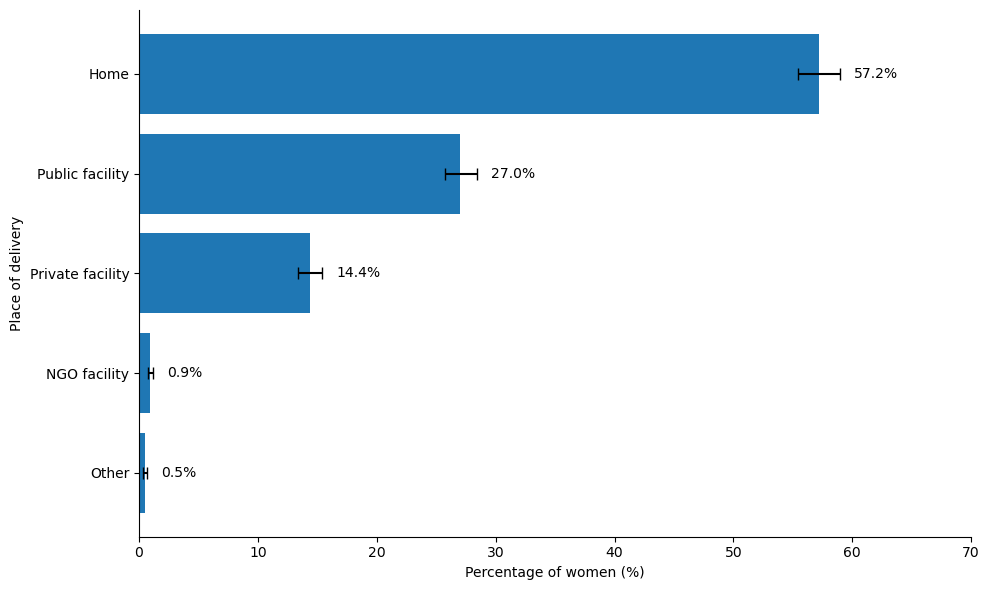

In [79]:
# Survey-weighted estimates for overall place of delivery (Gotten from the Samplics Analysis above).
delivery_data = pd.DataFrame({
    "Delivery location": [
        "Home",
        "NGO facility",
        "Other",
        "Private facility",
        "Public facility"
    ],
    "Estimate": [57.2114, 0.9186, 0.4812, 14.3536, 27.0352],
    "Lower CI": [55.4738, 0.7257, 0.3629, 13.3848, 25.7130],
    "Upper CI": [58.9313, 1.1621, 0.6378, 15.3802, 28.3995]
})

# Sorting categories from highest to lowest.
delivery_data = delivery_data.sort_values(
    "Estimate", ascending = True
)

# Calculating confidence interval margins.
lower_error = delivery_data["Estimate"] - delivery_data["Lower CI"]
upper_error = delivery_data["Upper CI"] - delivery_data["Estimate"]

# Creating the chart.
fig, ax = plt.subplots(figsize=(10, 6))

# Creating a horizontal bar chart.
ax.barh(
    delivery_data["Delivery location"],
    delivery_data["Estimate"],
    xerr = [lower_error, upper_error],
    capsize = 4
)

# Adding percentage labels beyond the upper confidence limit.
for position, (_, row) in enumerate(delivery_data.iterrows()):
    ax.text(
        row["Upper CI"] + 1.2,
        position,
        f'{row["Estimate"]:.1f}%',
        va = "center",
        fontsize = 10
    )

# Setting the labels.
ax.set_xlabel("Percentage of women (%)")
ax.set_ylabel("Place of delivery")
ax.set_xlim(0, 70)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("01_overall_place_of_delivery.png", dpi = 300, bbox_inches = "tight")
plt.show()

#### Interpretation.
- Home delivery accounted for the largest proportion of deliveries (57.2%), followed by public health facilities (27.0%) and private health facilities (14.4%).
- NGO facilities and other locations accounted for less than 1% each.

### Place of Delivery by Residence Chart.
- This is to compare Urban and Rural Delivery Patterns.

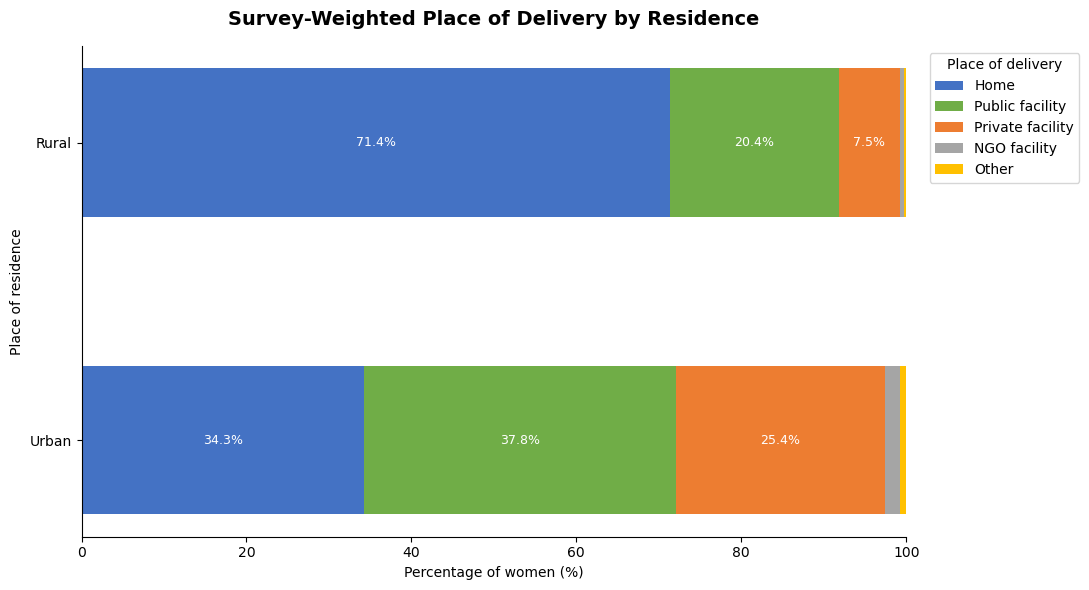

In [80]:
# Survey-weighted delivery percentages by residence.
residence_data = pd.DataFrame({
    "Residence": ["Urban", "Rural"],
    "Home": [34.2646, 71.3760],
    "Public facility": [37.7663, 20.4112],
    "Private facility": [25.4498, 7.5042],
    "NGO facility": [1.7923, 0.3792],
    "Other": [0.7269, 0.3295]
})

# Specifying colours for each delivery categories.
categories = [
    "Home",
    "Public facility",
    "Private facility",
    "NGO facility",
    "Other"
]

colors = [
    "#4472C4",
    "#70AD47",
    "#ED7D31",
    "#A5A5A5",
    "#FFC000"
]

# Creating the figure.
fig, ax = plt.subplots(figsize=(11, 6))

left = [0, 0]

# Drawing stacked bars.
for category, color in zip(categories, colors):

    values = residence_data[category].values

    ax.barh(
        residence_data["Residence"],
        values,
        left=left,
        label=category,
        color=color,
        height=0.5
    )

    # Adding labels to sufficiently large segments.
    for i, value in enumerate(values):
        if value >= 5:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white"
            )

    left = [left[i] + values[i] for i in range(len(values))]

# Formatting the Chart.
ax.set_title(
    "Survey-Weighted Place of Delivery by Residence",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Setting the labels.
ax.set_xlabel("Percentage of women (%)")
ax.set_ylabel("Place of residence")
ax.set_xlim(0, 100)

# Inputting the legend.
ax.legend(
    title="Place of delivery",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "02_delivery_by_residence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation.
- Home delivery was more prevalent among rural women (71.4%) than urban women (34.3%).
- Conversely, urban women recorded higher proportions of public facility (37.8% compared to rural women's 20.4%) and private facility (25.4% compared to rural women's 7.5%) deliveries.

### Place of Delivery by Education Chart.
- This is to show how delivery patterns vary by education.

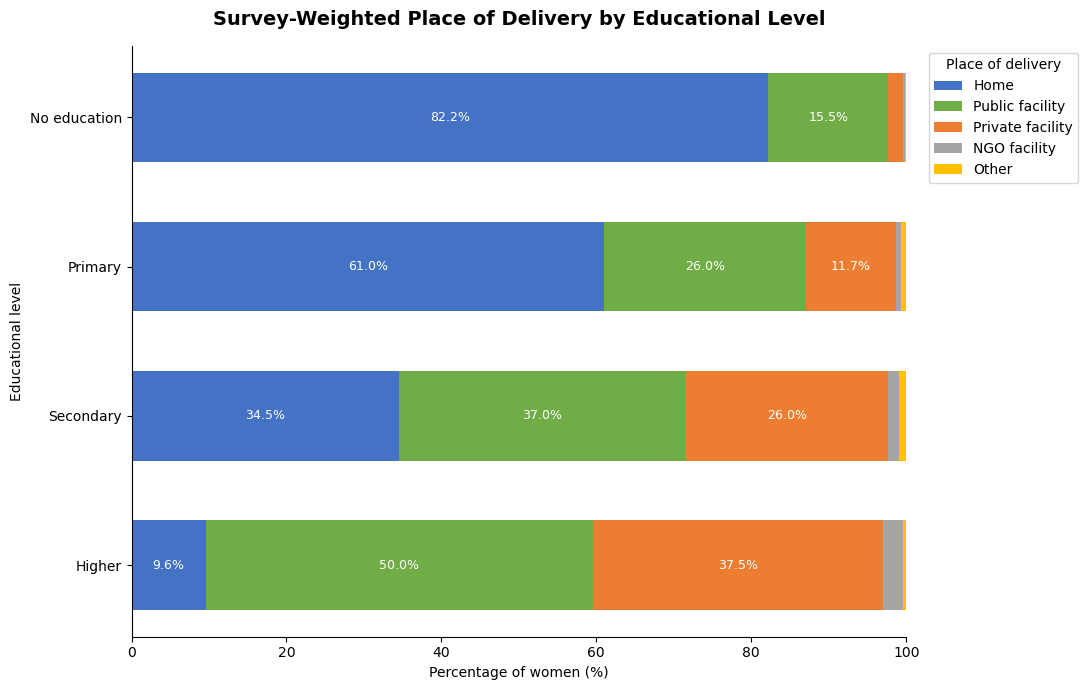

In [81]:
# Survey-weighted delivery percentages by education.
education_data = pd.DataFrame({
    "Education": [
        "No education",
        "Primary",
        "Secondary",
        "Higher"
    ],
    "Home": [82.1885, 60.9706, 34.5369, 9.5651],
    "Public facility": [15.4657, 26.0344, 37.0092, 49.9555],
    "Private facility": [1.9760, 11.6581, 26.0340, 37.4940],
    "NGO facility": [0.2229, 0.6836, 1.5099, 2.5245],
    "Other": [0.1469, 0.6533, 0.9100, 0.4608]
})

# Specifying colours for each delivery categories.
categories = [
    "Home",
    "Public facility",
    "Private facility",
    "NGO facility",
    "Other"
]

colors = [
    "#4472C4",
    "#70AD47",
    "#ED7D31",
    "#A5A5A5",
    "#FFC000"
]

# Creating the figure.
fig, ax = plt.subplots(figsize=(11, 7))

left = [0, 0, 0, 0]

for category, color in zip(categories, colors):

    values = education_data[category].values

    ax.barh(
        education_data["Education"],
        values,
        left=left,
        label=category,
        color=color,
        height=0.6
    )

    # Labelling sufficiently large segments.
    for i, value in enumerate(values):
        if value >= 5:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white"
            )

    left = [
        left[i] + values[i]
        for i in range(len(values))
    ]

# Arranging education levels in ascending order from top to bottom.
ax.invert_yaxis()

ax.set_title(
    "Survey-Weighted Place of Delivery by Educational Level",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Setting the labels.
ax.set_xlabel("Percentage of women (%)")
ax.set_ylabel("Educational level")
ax.set_xlim(0, 100)

# Inputting the legend.
ax.legend(
    title="Place of delivery",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "03_delivery_by_education.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation.
- Home delivery declined progressively with increasing educational attainment, from 82.2% among women with no education to 9.6% among women with higher education.
- Facility delivery showed the opposite pattern by increasing with increasing educational level.

### Place of Delivery by Wealth Group.
- This is to examine socioeconomic differences.

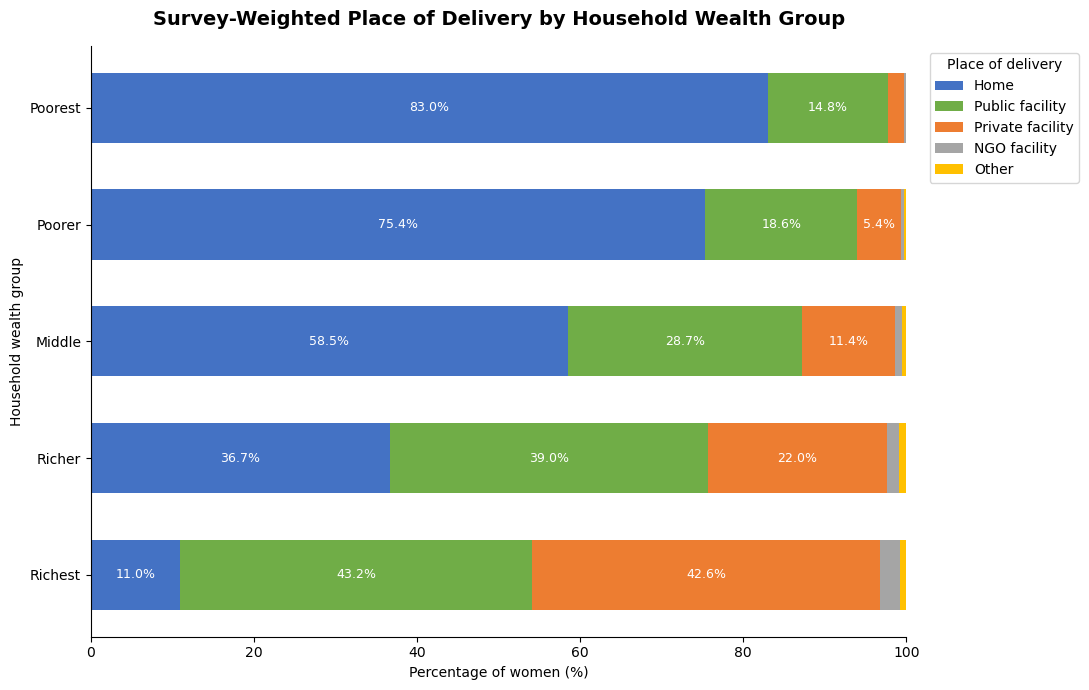

In [82]:
# Survey-weighted delivery percentages by wealth group.
wealth_data = pd.DataFrame({
    "Wealth group": [
        "Poorest",
        "Poorer",
        "Middle",
        "Richer",
        "Richest"
    ],
    "Home": [83.0203, 75.3709, 58.4628, 36.6906, 10.9789],
    "Public facility": [14.7530, 18.6381, 28.7326, 38.9543, 43.1643],
    "Private facility": [1.9478, 5.3717, 11.3855, 22.0422, 42.5834],
    "NGO facility": [0.2006, 0.3108, 0.8451, 1.3805, 2.5349],
    "Other": [0.0782, 0.3086, 0.5740, 0.9324, 0.7385]
})

# Specifying colours for each categories.
categories = [
    "Home",
    "Public facility",
    "Private facility",
    "NGO facility",
    "Other"
]

colors = [
    "#4472C4",
    "#70AD47",
    "#ED7D31",
    "#A5A5A5",
    "#FFC000"
]

# Creating the figure.
fig, ax = plt.subplots(figsize=(11, 7))

left = [0, 0, 0, 0, 0]

for category, color in zip(categories, colors):

    values = wealth_data[category].values

    # Creating a horizontal bar chart.
    ax.barh(
        wealth_data["Wealth group"],
        values,
        left=left,
        label=category,
        color=color,
        height=0.6
    )

    # Labelling sufficiently large segments.
    for i, value in enumerate(values):
        if value >= 5:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white"
            )

    left = [
        left[i] + values[i]
        for i in range(len(values))
    ]

# Arranging wealth groups from poorest to richest.
ax.invert_yaxis()

# Setting the title.
ax.set_title(
    "Survey-Weighted Place of Delivery by Household Wealth Group",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Setting the labels.
ax.set_xlabel("Percentage of women (%)")
ax.set_ylabel("Household wealth group")
ax.set_xlim(0, 100)

# Inputting the legend.
ax.legend(
    title="Place of delivery",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "04_delivery_by_wealth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation.
- Home delivery was highest among the poorest women (83.0%) and lowest among the richest women (11.0%).
- Public and Private facility delivery increased considerably across wealth groups, with Public Facility reaching 43.2% and Private Facility reaching 42.6% among the richest women.

### Mean Antenatal Visits Chart.
- This is to present the estimated mean and its uncertainty.

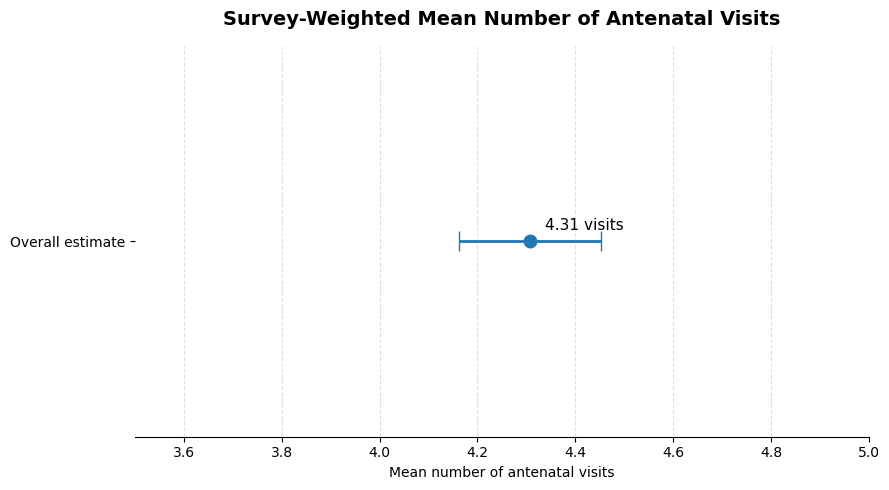

In [83]:
# Survey-weighted mean antenatal visits.
mean_visits = 4.306984
lower_ci = 4.161736
upper_ci = 4.452231

# Calculating confidence interval margins.
lower_error = mean_visits - lower_ci
upper_error = upper_ci - mean_visits

# Creating the figure.
fig, ax = plt.subplots(figsize=(9, 5))

# Creating the error bar.
ax.errorbar(
    mean_visits,
    1,
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    markersize=9,
    capsize=7,
    elinewidth=2
)

# Adding the estimate label.
ax.text(
    mean_visits + 0.03,
    1.04,
    f"{mean_visits:.2f} visits",
    fontsize=11,
    va="center"
)

# Setting the chart title.
ax.set_title(
    "Survey-Weighted Mean Number of Antenatal Visits",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Setting the chart labels.
ax.set_xlabel("Mean number of antenatal visits")
ax.set_yticks([1])
ax.set_yticklabels(["Overall estimate"])

ax.set_xlim(3.5, 5.0)
ax.set_ylim(0.5, 1.5)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "05_mean_antenatal_visits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation.
- The survey-weighted mean number of antenatal visits was 4.31 (95% Confidence Interval: 4.16–4.45).